In [1]:
# ==================================================================================================
# FINAL SCRIPT: SAINT PETERSBURG FLOOD MODEL (FULL CITY)
# ==================================================================================================
!pip install -q pystac-client planetary-computer rioxarray osmnx geopandas rasterio folium mapclassify

import numpy as np
import geopandas as gpd
import osmnx as ox
import rioxarray
from rioxarray.merge import merge_arrays
import pystac_client
import planetary_computer
from shapely.geometry import box, mapping
import folium
from rasterio.features import shapes

# Настройки
ox.settings.use_cache = True
ox.settings.log_console = False
# Используем метрическую систему для расчетов (UTM Zone 36N)
CRS_METRIC = "EPSG:32636"

print("🚀 Начинаем расчет для всего Санкт-Петербурга...")

# ==================================================================================================
# ШАГ 1: ОПРЕДЕЛЕНИЕ ГРАНИЦ (ПРЯМОУГОЛЬНИК)
# ==================================================================================================
# Координаты охватывают: Кронштадт (З), Колпино (В), Пушкин (Ю), Парнас (С)
# Порядок: [min_lon, min_lat, max_lon, max_lat]
BBOX_COORDS = [29.60, 59.75, 30.60, 60.10] 

# Создаем объект геометрии для поиска
bbox_geom = box(*BBOX_COORDS)
aoi_poly = gpd.GeoDataFrame({'geometry': [bbox_geom]}, crs="EPSG:4326")
aoi_utm = aoi_poly.to_crs(CRS_METRIC)

print(f"📍 Охват: {BBOX_COORDS}")
FLOOD_LEVEL = 3.0  # Уровень наводнения (метры)

# ==================================================================================================
# ШАГ 2 (ИСПРАВЛЕННЫЙ): ЗАГРУЗКА РЕЛЬЕФА (ALOS World 3D + Fallback)
# ==================================================================================================
print("\n📡 Запрос спутниковых данных...")

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Функция для безопасной загрузки
def fetch_dem(bbox, collection_id):
    print(f"   Пробуем источник: {collection_id}...")
    try:
        search = catalog.search(
            collections=[collection_id],
            bbox=bbox,
        )
        items = search.item_collection()
        print(f"   Найдено тайлов: {len(items)}")
        
        if len(items) > 0:
            dem_clips = []
            for item in items:
                href = item.assets["data"].href
                # ALOS и Copernicus могут иметь разные ключи для данных, проверяем
                if collection_id == "alos-dem":
                    # У ALOS часто ключ просто 'data' или он требует хитрой обработки
                    # Пробуем стандартный подход
                    pass
                
                rds = rioxarray.open_rasterio(href, masked=True)
                rds = rds.rio.clip_box(*bbox, crs="EPSG:4326")
                dem_clips.append(rds)
            
            merged = merge_arrays(dem_clips)
            return merged
    except Exception as e:
        print(f"   ⚠️ Ошибка источника {collection_id}: {e}")
        return None
    return None

# 1. Пробуем ALOS (Япония) - надежнее для севера
dem = fetch_dem(BBOX_COORDS, "alos-dem")

# 2. Если ALOS не сработал, пробуем снова Copernicus (Европа)
if dem is None:
    dem = fetch_dem(BBOX_COORDS, "copernicus-dem-glo-30")

# 3. ПОСЛЕДНИЙ РУБЕЖ: ГЕНЕРАЦИЯ ЗАГЛУШКИ
# Если API Microsoft недоступен (бывает), генерируем синтетический рельеф,
# чтобы вы могли проверить код отрисовки карты.
if dem is None:
    print("\n⚠️ ВНИМАНИЕ: Спутниковые данные недоступны. Генерируем тестовый рельеф.")
    
    # Создаем сетку координат
    x = np.linspace(BBOX_COORDS[0], BBOX_COORDS[2], 500)
    y = np.linspace(BBOX_COORDS[1], BBOX_COORDS[3], 500)
    X, Y = np.meshgrid(x, y)
    
    # Создаем наклонную плоскость (имитация берега: запад ниже, восток выше)
    # Высоты от -2м до 10м
    Z = (X - BBOX_COORDS[0]) * 10 - 2
    
    from xarray import DataArray
    from rasterio.transform import from_bounds
    
    transform = from_bounds(BBOX_COORDS[0], BBOX_COORDS[1], BBOX_COORDS[2], BBOX_COORDS[3], 500, 500)
    
    dem = DataArray(
        Z, coords={'y': y, 'x': x}, dims=('y', 'x'),
        attrs={'res': 0.002}
    )
    dem.rio.write_crs("EPSG:4326", inplace=True)
    dem.rio.write_transform(transform, inplace=True)
    dem.rio.write_nodata(-9999, inplace=True)
    print("✅ Тестовый рельеф создан.")
else:
    print("✅ Спутниковые данные успешно загружены.")

# ПОСТ-ОБРАБОТКА (Одинакова для всех источников)
# Перепроецируем в метрическую систему
dem = dem.rio.reproject(CRS_METRIC)
dem = dem.rio.clip(aoi_utm.geometry, aoi_utm.crs)

# Автокалибровка нуля (по самому низкому значению)
# Это нужно, чтобы убрать артефакты геоида
flat_vals = dem.values.flatten()
valid_vals = flat_vals[flat_vals > -100] # убираем совсем ошибочные нодаты
if len(valid_vals) > 0:
    min_val = np.nanpercentile(valid_vals, 1)
    if abs(min_val) > 1.0: # Если смещение больше 1 метра
        print(f"   ⚖️ Калибровка высоты: сдвиг на {-min_val:.2f} м.")
        dem = dem - min_val

print("✅ Данные готовы к анализу.")
# ==================================================================================================
# ШАГ 3: РАСЧЕТ ЗАТОПЛЕНИЯ
# ==================================================================================================
print(f"\n🌊 Моделирование уровня воды: {FLOOD_LEVEL} м...")

flood_mask = dem <= FLOOD_LEVEL
flood_mask = flood_mask.astype('uint8')

# Векторизация зоны затопления
mask_arr = flood_mask.values
if len(mask_arr.shape) == 3: mask_arr = mask_arr[0]

results = (
    {'properties': {'val': v}, 'geometry': s}
    for i, (s, v) in enumerate(
        shapes(mask_arr, mask=mask_arr==1, transform=dem.rio.transform())
    )
)
geoms = list(results)

if len(geoms) > 0:
    flood_poly = gpd.GeoDataFrame.from_features(geoms, crs=CRS_METRIC)
    flood_poly = flood_poly.dissolve()
    flood_poly = flood_poly.reset_index(drop=True)
    
    # ==============================================================================================
    # ШАГ 4: АНАЛИЗ ТЕРРИТОРИЙ (OSM)
    # ==============================================================================================
    print("\n🏗️ Загрузка карты землепользования (Landuse) из OSM...")
    print("   Это может занять до 2-3 минут для всего города...")
    
    # Качаем только landuse по BBox (это быстрее, чем buildings)
    try:
        landuse = ox.features_from_bbox(bbox=BBOX_COORDS, tags={'landuse': True})
        landuse = landuse.to_crs(CRS_METRIC)
        landuse = landuse[landuse.geometry.type.isin(['Polygon', 'MultiPolygon'])]
        landuse = landuse.reset_index(drop=True)
        
        print(f"   Обработка пересечений с {len(landuse)} зонами...")
        
        flooded_landuse = gpd.overlay(landuse, flood_poly, how='intersection')
        
        if not flooded_landuse.empty:
            flooded_landuse['area_ha'] = flooded_landuse.geometry.area / 10000
            
            print("\n📊 === ИТОГОВЫЙ ОТЧЕТ (Уровень +3м) ===")
            stats = flooded_landuse.groupby('landuse')['area_ha'].sum().sort_values(ascending=False).reset_index()
            print(stats.head(10))
            
            # Сохранение статистики в CSV
            stats.to_csv("spb_flood_stats.csv", index=False)
            
            # ==========================================================================================
            # ШАГ 5: ИНТЕРАКТИВНАЯ КАРТА
            # ==========================================================================================
            print("\n🗺️ Сборка веб-карты...")
            m = folium.Map(location=[59.93, 30.31], zoom_start=11, tiles='CartoDB dark_matter')
            
            # Зона затопления (синий)
            # Упрощаем геометрию для быстрого отображения в браузере (tolerance=10m)
            simple_flood = flood_poly.to_crs(epsg=4326).simplify(10, preserve_topology=True)
            
            folium.GeoJson(
                simple_flood,
                name='Зона затопления',
                style_function=lambda x: {'fillColor': '#00BFFF', 'color': 'none', 'fillOpacity': 0.5}
            ).add_to(m)
            
            # Пострадавшие зоны (красный)
            simple_risk = flooded_landuse.to_crs(epsg=4326).simplify(10, preserve_topology=True)
            
            folium.GeoJson(
                simple_risk,
                name='Затопленные территории',
                style_function=lambda x: {'fillColor': '#FF4500', 'color': 'black', 'weight': 0.5, 'fillOpacity': 0.6},
                tooltip=folium.GeoJsonTooltip(fields=['landuse', 'area_ha'], aliases=['Тип', 'Площадь (га)'], localize=True)
            ).add_to(m)
            
            folium.LayerControl().add_to(m)
            m.save("spb_full_flood.html")
            print("✅ Готово! Откройте файл spb_full_flood.html")
            
        else:
            print("Зоны риска не пересеклись с важной инфраструктурой.")
            
    except Exception as e:
        print(f"Ошибка при обработке OSM: {e}")

else:
    print("Наводнения не обнаружено.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.2/62.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.5/101.5 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 338.4/338.4 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 68.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 882.2/882.2 kB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.7/207.7 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 85.3 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.12.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you hav

/tmp/ipykernel_94/578071875.py:128: RuntimeWarning: invalid value encountered in greater
  valid_vals = flat_vals[flat_vals > -100] # убираем совсем ошибочные нодаты


✅ Данные готовы к анализу.

🌊 Моделирование уровня воды: 3.0 м...

🏗️ Загрузка карты землепользования (Landuse) из OSM...
   Это может занять до 2-3 минут для всего города...
   Обработка пересечений с 45337 зонами...

📊 === ИТОГОВЫЙ ОТЧЕТ (Уровень +3м) ===
        landuse     area_ha
0    industrial  365.096501
1  construction  219.242297
2      military  183.907258
3   residential  112.826157
4         grass   98.020609
5    allotments   85.434477
6        retail   25.679851
7    commercial    9.667094
8      cemetery    8.666228
9      farmland    8.557712

🗺️ Сборка веб-карты...
Ошибка при обработке OSM: The field landuse is not available in the data. Choose from: ().


In [2]:
# ==================================================================================================
# ШАГ 5 (ИСПРАВЛЕННЫЙ): СБОРКА КАРТЫ
# Исправлена ошибка потери атрибутов при упрощении геометрии
# ==================================================================================================
print("\n🗺️ Сборка веб-карты (Fix)...")

# Создаем карту
m = folium.Map(location=[59.93, 30.31], zoom_start=11, tiles='CartoDB dark_matter')

# --- 1. Слой зоны затопления ---
# Создаем копию и упрощаем геометрию ВНУТРИ GeoDataFrame, чтобы не потерять структуру
if 'flood_poly' in locals() and not flood_poly.empty:
    simple_flood = flood_poly.to_crs(epsg=4326).copy()
    # Упрощаем геометрию (10 метров точность), сохраняя объект GeoDataFrame
    simple_flood['geometry'] = simple_flood.geometry.simplify(10, preserve_topology=True)
    
    folium.GeoJson(
        simple_flood,
        name='Зона затопления (Сценарий +3м)',
        style_function=lambda x: {'fillColor': '#00BFFF', 'color': 'none', 'fillOpacity': 0.4}
    ).add_to(m)

# --- 2. Слой пострадавших территорий ---
if 'flooded_landuse' in locals() and not flooded_landuse.empty:
    # Копируем и упрощаем
    simple_risk = flooded_landuse.to_crs(epsg=4326).copy()
    simple_risk['geometry'] = simple_risk.geometry.simplify(10, preserve_topology=True)
    
    # Очищаем данные от NaN перед визуализацией (на всякий случай)
    simple_risk['area_ha'] = simple_risk['area_ha'].fillna(0).round(2)
    simple_risk['landuse'] = simple_risk['landuse'].fillna('unknown')
    
    # Функция стиля в зависимости от типа
    def get_color(feature):
        lu = feature['properties']['landuse']
        if lu == 'residential': return '#FF0000' # Красный для жилья
        if lu == 'industrial': return '#A52A2A'  # Коричневый для заводов
        if lu == 'military': return '#000000'    # Черный для военных
        return '#FFA500' # Оранжевый для остального

    folium.GeoJson(
        simple_risk,
        name='Затопленная инфраструктура',
        style_function=lambda x: {
            'fillColor': get_color(x), 
            'color': 'none', 
            'fillOpacity': 0.7
        },
        tooltip=folium.GeoJsonTooltip(
            fields=['landuse', 'area_ha'],
            aliases=['Тип объекта:', 'Затоплено (га):'],
            localize=True
        )
    ).add_to(m)

# Добавляем легенду слоев
folium.LayerControl().add_to(m)

# Сохраняем
output_file = "spb_flood_map_final.html"
m.save(output_file)
print(f"✅ Карта успешно создана: {output_file}")
print("👇 Скачайте файл spb_flood_map_final.html из панели Output справа.")

# Отображаем (может подтормаживать, если зон очень много)
m


🗺️ Сборка веб-карты (Fix)...
✅ Карта успешно создана: spb_flood_map_final.html
👇 Скачайте файл spb_flood_map_final.html из панели Output справа.


In [3]:
# Диагностика + проба загрузки из Copernicus DEM (GLO-30 / GLO-90)
import pystac_client, planetary_computer, rioxarray, traceback

collections_to_try = [
    "cop-dem-glo-30",  # Copernicus DEM 30m (public subset)
    "cop-dem-glo-90",  # Copernicus DEM 90m (global)
    "copernicus-dem",  # иногда бывает такое имя
]

catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)

for coll in collections_to_try:
    try:
        print(f"\n--- Поиск в коллекции: {coll} ---")
        search = catalog.search(collections=[coll], bbox=bbox, limit=20)
        items = list(search.get_items())
        print("Найдено items:", len(items))
        if len(items) == 0:
            continue
        # Показать первые items и assets
        for i, it in enumerate(items[:5]):
            print(f" item {i}: id={it.id}, bbox={getattr(it, 'bbox', None)}")
            print("  assets:", list(it.assets.keys()))
        # Попробуем подписать и открыть asset 'data' или первый георастр
        it0 = items[0]
        # Попытаемся найти подходящий asset
        candidate = None
        for key, a in it0.assets.items():
            href = a.href
            # Обычно asset с глифом 'data' или 'file' или 'raster' содержит tiff
            if href.lower().endswith(('.tif', '.tiff', '.vrt', '.zip')):
                candidate = a
                break
        if candidate is None:
            # fallback: возьмём любой и попробуем
            candidate = list(it0.assets.values())[0]
        signed = planetary_computer.sign(candidate.href)
        print(" Signed URL (preview):", signed[:200])
        try:
            ds = rioxarray.open_rasterio(signed, masked=True)
            print(" rioxarray.open_rasterio succeeded. shape:", getattr(ds, 'shape', None), "crs:", getattr(ds, 'rio', None) and ds.rio.crs)
            break  # если успешно, выходим из цикла коллекций
        except Exception as e:
            print(" rioxarray.open_rasterio failed:", e)
            traceback.print_exc()
    except Exception as e:
        print("Ошибка при поиске/обработке коллекции", coll, ":", e)



--- Поиск в коллекции: cop-dem-glo-30 ---
Ошибка при поиске/обработке коллекции cop-dem-glo-30 : name 'bbox' is not defined

--- Поиск в коллекции: cop-dem-glo-90 ---
Ошибка при поиске/обработке коллекции cop-dem-glo-90 : name 'bbox' is not defined

--- Поиск в коллекции: copernicus-dem ---
Ошибка при поиске/обработке коллекции copernicus-dem : name 'bbox' is not defined


In [8]:
# Полный рабочий блок: загрузка DEM (copernicus GLO-30/GLO-90), калибровка по воде, моделирование затопления, визуализация
# Важно: перед запуском убедитесь, что установлены нужные пакеты: pystac-client, planetary-computer, rioxarray, osmnx, geopandas, rasterio, folium

import os
import numpy as np
import geopandas as gpd
import osmnx as ox
import rioxarray
from rioxarray.merge import merge_arrays
import pystac_client
import planetary_computer
from rasterio.features import shapes
from shapely.geometry import shape, box, mapping
import folium
from affine import Affine
from xarray import DataArray
from rasterio.enums import Resampling
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Параметры (можете менять) ----
PLACE_NAME = "Vasilyevsky Island, Saint Petersburg, Russia"
FLOOD_LEVEL_METERS = 3.0
CRS_METRIC = "EPSG:32636"  # UTM zone 36N, метрическая (под СПб)
OUT_DEM_FILENAME = "copernicus_dem_clipped.tif"
MAP_FILENAME = "spb_flood_analysis.html"
FALLBACK_MAX_ELEV = 5.0  # максимум в fallback DEM (м)

# Настройки osmnx
ox.settings.use_cache = True
ox.settings.log_console = False

print("📍 Локация:", PLACE_NAME)
print("🌊 Сценарий затопления: +{:.2f} м".format(FLOOD_LEVEL_METERS))

# -------------------------
# Получаем AOI и bbox
# -------------------------
aoi_gdf = ox.geocode_to_gdf(PLACE_NAME)
aoi_utm = aoi_gdf.to_crs(CRS_METRIC)
bbox = list(aoi_gdf.total_bounds)  # [minx, miny, maxx, maxy] WGS84
print("AOI bbox (WGS84):", bbox)

# -------------------------
# Поиск DEM в Planetary Computer (Copernicus GLO-30 -> GLO-90)
# -------------------------
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)

collections_to_try = ["cop-dem-glo-30", "cop-dem-glo-90", "copernicus-dem", "cop-dem"]

dem = None
dem_src_href = None

for coll in collections_to_try:
    try:
        print(f"\n🔎 Поиск в коллекции: {coll} ...")
        search = catalog.search(collections=[coll], bbox=bbox, limit=50)
        items = list(search.get_items())
        print("  Найдено items:", len(items))
        if len(items) == 0:
            continue

        # Найдём первый пригодный asset (GeoTIFF/COG)
        candidate_asset = None
        for it in items:
            for k, a in it.assets.items():
                href = a.href
                if isinstance(href, str) and href.lower().endswith(('.tif', '.tiff', '.vrt', '.zip')):
                    candidate_asset = a
                    item_for_signed = it
                    break
            if candidate_asset is not None:
                break

        if candidate_asset is None:
            # возьмём любой asset из первого item и попробуем
            it0 = items[0]
            if len(it0.assets) > 0:
                candidate_asset = list(it0.assets.values())[0]
                item_for_signed = it0
            else:
                continue

        # подпишем и попробуем открыть
        signed = planetary_computer.sign(candidate_asset.href)
        print("  Подписанный href (preview):", signed[:120])
        try:
            ds = rioxarray.open_rasterio(signed, masked=True)
            print("  Успешно открыт raster: shape", ds.shape, "CRS", ds.rio.crs)
            dem = ds  # временно держим в WGS84
            dem_src_href = signed
            break
        except Exception as e_open:
            print("  Ошибка при открытии подписанного asset:", e_open)
            continue

    except Exception as e_coll:
        print("  Ошибка при поиске в коллекции", coll, ":", e_coll)
        continue

# -------------------------
# Если ничего не найдено — создаём fallback DEM (с геопривязкой)
# -------------------------
if dem is None:
    print("\n⚠️ DEM не найдена в коллекциях. Создаём fallback DEM (синтетическая заглушка).")
    xmin, ymin, xmax, ymax = aoi_utm.total_bounds
    res = 10.0  # метров/пиксель
    nx = max(2, int(np.ceil((xmax - xmin) / res)))
    ny = max(2, int(np.ceil((ymax - ymin) / res)))
    x_coords = xmin + (np.arange(nx) + 0.5) * res
    y_coords = ymax - (np.arange(ny) + 0.5) * res
    X, Y = np.meshgrid(x_coords, y_coords)
    Z = (Y - ymin) / max((ymax - ymin), 1e-6) * FALLBACK_MAX_ELEV
    dem = DataArray(Z[np.newaxis, :, :], coords={"band":[1], "y": y_coords, "x": x_coords}, dims=("band","y","x"))
    # set spatial dims/transform/crs
    dem = dem.rio.set_spatial_dims(x_dim="x", y_dim="y", inplace=False)
    transform = Affine(res, 0.0, xmin, 0.0, -res, ymax)
    dem.rio.write_transform(transform, inplace=True)
    dem.rio.write_crs(CRS_METRIC, inplace=True)
    print("  Fallback DEM создан: shape", dem.shape, "CRS", dem.rio.crs)
else:
    # У нас есть дем в EPSG:4326. Перепроецируем в CRS_METRIC
    print("\n🔁 Перепроекция DEM в метрическую систему:", CRS_METRIC)
    try:
        dem = dem.rio.reproject(CRS_METRIC, resampling=Resampling.bilinear)
        print("  Новая форма:", dem.shape, "CRS:", dem.rio.crs)
    except Exception as e_reproj:
        print("  Ошибка перепроекции:", e_reproj)
        # если не удалось, оставим как есть

# -------------------------
# Клиппинг по AOI (metric CRS expected)
# -------------------------
print("\n✂️ Обрезка DEM по AOI...")
try:
    # если dem CRS != aoi_utm.crs — убедимся
    if dem.rio.crs != aoi_utm.crs:
        # aoi_utm уже в CRS_METRIC по дизайну; если нет — перепроецируем
        aoi_for_clip = aoi_utm
    else:
        aoi_for_clip = aoi_utm
    dem_clipped = dem.rio.clip(aoi_for_clip.geometry, aoi_for_clip.crs, drop=False)
    dem = dem_clipped
    print("  Обрезка выполнена. Итоговая форма:", dem.shape)
except Exception as e_clip:
    print("  Ошибка при клиппинге DEM:", e_clip)

# Сохраняем локально, чтобы ссылка на исход не истекла
try:
    print("\n💾 Сохраняю DEM локально:", OUT_DEM_FILENAME)
    dem.rio.to_raster(OUT_DEM_FILENAME)
    print("  Сохранено.")
except Exception as e_save:
    print("  Ошибка сохранения DEM:", e_save)

# -------------------------
# Калибровка высот по воде (OSM)
# -------------------------
print("\n📏 Калибровка высот по полигонам воды OSM...")
try:
    water = ox.features_from_place(PLACE_NAME, tags={'natural': 'water', 'waterway': 'riverbank'})
    if not water.empty:
        water = water.to_crs(CRS_METRIC)
        try:
            water_mask = dem.rio.clip(water.geometry, water.crs, drop=False, invert=False)
            vals = water_mask.values.flatten()
            vals = vals[~np.isnan(vals)]
            if vals.size > 0:
                offset = float(np.nanmedian(vals))
                dem = dem - offset
                print(f"  Применён сдвиг высот (медиана по воде): {offset:.2f} м")
            else:
                print("  ⚠️ Вектор воды присутствует, но нет валидных DEM значений внутри полигона.")
        except Exception as e_wclip:
            print("  Ошибка при клиппинге DEM по воде:", e_wclip)
    else:
        print("  ⚠️ Слой воды OSM пуст — пропускаем калибровку.")
except Exception as e_osm:
    print("  Ошибка запроса OSM:", e_osm)

# -------------------------
# Моделирование затопления
# -------------------------
print(f"\n🌊 Моделирование затопления: уровень <= {FLOOD_LEVEL_METERS} м ...")
try:
    flood_mask = dem <= FLOOD_LEVEL_METERS
    # Приведём к uint8 для shapes
    arr = flood_mask.values.astype('uint8')
    if arr.ndim == 3:
        # берем первую полосу, если есть band axis
        arr2 = arr[0]
    else:
        arr2 = arr
    transform = dem.rio.transform()
    # получаем полигоны
    results = (
        {'properties': {'val': int(v)}, 'geometry': s}
        for i, (s, v) in enumerate(
            shapes(arr2, mask=arr2 == 1, transform=transform)
        )
    )
    geoms = list(results)
    if len(geoms) > 0:
        flood_poly = gpd.GeoDataFrame.from_features(geoms, crs=CRS_METRIC).dissolve()
        print("  Найдены полигоны затопления.")
    else:
        flood_poly = gpd.GeoDataFrame(columns=['geometry'], crs=CRS_METRIC)
        print("  Затопления не обнаружено при данном уровне.")
except Exception as e_flood:
    print("  Ошибка при расчёте маски затопления:", e_flood)
    flood_poly = gpd.GeoDataFrame(columns=['geometry'], crs=CRS_METRIC)

# -------------------------
# Загрузка данных землепользования и оценка ущерба (OSM via osmnx)
# -------------------------
print("\n🏗️ Анализ затронутого землепользования...")
try:
    landuse = ox.features_from_place(PLACE_NAME, tags={'landuse': True})
    if not landuse.empty:
        landuse = landuse.to_crs(CRS_METRIC)
        landuse = landuse[landuse.geometry.type.isin(['Polygon', 'MultiPolygon'])]
        if not flood_poly.empty:
            flooded_landuse = gpd.overlay(landuse, flood_poly, how='intersection')
            if not flooded_landuse.empty:
                flooded_landuse['flooded_area_ha'] = flooded_landuse.geometry.area / 10000.0
                stats = flooded_landuse.groupby('landuse')['flooded_area_ha'].sum().sort_values(ascending=False).reset_index()
                print("  Результаты (top):")
                print(stats.head(10))
            else:
                flooded_landuse = gpd.GeoDataFrame(columns=['landuse','geometry'], crs=CRS_METRIC)
                print("  Нет пересечений землепользования с зоной затопления.")
        else:
            flooded_landuse = gpd.GeoDataFrame(columns=['landuse','geometry'], crs=CRS_METRIC)
            print("  Зона затопления пуста — пропускаем пересечение.")
    else:
        flooded_landuse = gpd.GeoDataFrame(columns=['landuse','geometry'], crs=CRS_METRIC)
        print("  Не удалось загрузить данные landuse из OSM.")
except Exception as e_land:
    print("  Ошибка при обработке landuse:", e_land)
    flooded_landuse = gpd.GeoDataFrame(columns=['landuse','geometry'], crs=CRS_METRIC)

# -------------------------
# Визуализация (folium)
# -------------------------
print("\n🗺️ Генерация интерактивной карты...")
try:
    centroid = aoi_gdf.geometry.centroid.iloc[0]
    m = folium.Map(location=[centroid.y, centroid.x], zoom_start=13, tiles='CartoDB positron')

    folium.GeoJson(aoi_gdf, name='Границы района',
                   style_function=lambda x: {'color': 'gray', 'fill': False, 'dashArray': '5,5'}).add_to(m)

    if not flood_poly.empty:
        flood_wgs = flood_poly.to_crs(epsg=4326)
        folium.GeoJson(flood_wgs, name='Зона затопления',
                       style_function=lambda x: {'fillColor': '#00BFFF', 'color': 'none', 'fillOpacity': 0.5}).add_to(m)

    if not flooded_landuse.empty:
        risk_wgs = flooded_landuse.to_crs(epsg=4326)
        folium.GeoJson(risk_wgs, name='Затопленная инфраструктура',
                       style_function=lambda x: {'fillColor': '#FF4500', 'color': 'black', 'weight': 0.5, 'fillOpacity': 0.6},
                       tooltip=folium.GeoJsonTooltip(fields=['landuse', 'flooded_area_ha'],
                                                     aliases=['Тип:', 'Площадь (га):'], localize=True)).add_to(m)

    folium.LayerControl().add_to(m)
    
    m.save(MAP_FILENAME)
    m
    print("  Карта сохранена:", MAP_FILENAME)
except Exception as e_map:
    print("  Ошибка при создании карты:", e_map)

print("\n✅ Готово. Файлы:")
print(" - DEM локально:", OUT_DEM_FILENAME if os.path.exists(OUT_DEM_FILENAME) else "(не сохранён)")
print(" - Карта:", MAP_FILENAME if os.path.exists(MAP_FILENAME) else "(не сохранена)")

# --- Конец ---
m

📍 Локация: Vasilyevsky Island, Saint Petersburg, Russia
🌊 Сценарий затопления: +3.00 м
AOI bbox (WGS84): [30.1777808, 59.9184544, 30.3077042, 59.9544329]

🔎 Поиск в коллекции: cop-dem-glo-30 ...
  Найдено items: 1
  Подписанный href (preview): https://elevationeuwest.blob.core.windows.net/copernicus-dem/COP30_hh/Copernicus_DSM_COG_10_N59_00_E030_00_DEM.tif?st=20
  Успешно открыт raster: shape (1, 3600, 2400) CRS EPSG:4326

🔁 Перепроекция DEM в метрическую систему: EPSG:32636
  Новая форма: (1, 3928, 2104) CRS: EPSG:32636

✂️ Обрезка DEM по AOI...
  Обрезка выполнена. Итоговая форма: (1, 3928, 2104)

💾 Сохраняю DEM локально: copernicus_dem_clipped.tif
  Сохранено.

📏 Калибровка высот по полигонам воды OSM...
  Применён сдвиг высот (медиана по воде): 0.00 м

🌊 Моделирование затопления: уровень <= 3.0 м ...
  Найдены полигоны затопления.

🏗️ Анализ затронутого землепользования...
  Результаты (top):
        landuse  flooded_area_ha
0   residential        56.669549
1  construction        4

/tmp/ipykernel_94/1659042264.py:248: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroid = aoi_gdf.geometry.centroid.iloc[0]


  Карта сохранена: spb_flood_analysis.html

✅ Готово. Файлы:
 - DEM локально: copernicus_dem_clipped.tif
 - Карта: spb_flood_analysis.html


In [5]:
!pip install -q osmnx
!pip install -q rioxarray
!pip install -q pystac-client
!pip install -q planetary-computer

In [6]:
import requests
from shapely.geometry import LineString, shape, mapping, Polygon, MultiPolygon
from shapely.ops import linemerge, unary_union, polygonize
import time
import json

In [7]:
import os
from pathlib import Path
import requests
import geopandas as gpd
import osmnx as ox
import rioxarray
from rioxarray.merge import merge_arrays
import pystac_client
import planetary_computer
from rasterio.enums import Resampling
import folium
from matplotlib import cm
import numpy as np
import concurrent.futures

# -------------------------
# Параметры
# -------------------------
CITY_NAME = "Saint Petersburg, Russia"
CRS_METRIC = "EPSG:32636"  # UTM zone 36N
OUTPUT_DIR = Path("arcticdem_spb")
OUTPUT_DIR.mkdir(exist_ok=True)
MAX_WORKERS = 6
PGC_STAC_URL = "https://pgc-opendata-dems.s3.us-west-2.amazonaws.com/pgc-data-stac.json"
COLLS = ["arcticdem-mosaic", "arcticdem-strips", "arcticdem"]
ASSET_SUFFIXES = (".tif", ".vrt")

# -------------------------
# Функции
# -------------------------
def safe_name(s):
    return "".join(c if c.isalnum() or c in " _-." else "_" for c in s).strip()

def download_url(url, outpath, session=None):
    outpath = Path(outpath)
    outpath.parent.mkdir(parents=True, exist_ok=True)
    sess = session or requests.Session()
    try:
        with sess.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(outpath, "wb") as f:
                for chunk in r.iter_content(chunk_size=1024*1024):
                    if chunk:
                        f.write(chunk)
        return outpath
    except:
        return None

def find_spb_districts():
    print("Получаем районы СПб (admin_level=8)...")
    city = ox.geocode_to_gdf(CITY_NAME)
    city_poly = city.geometry.iloc[0]
    minx, miny, maxx, maxy = city_poly.bounds
    south, west, north, east = miny, minx, maxy, maxx
    query = f"""
    [out:json][timeout:180];
    relation["boundary"="administrative"]["admin_level"="8"]({south},{west},{north},{east});
    out geom;
    """
    url = "https://overpass-api.de/api/interpreter"
    r = requests.post(url, data={"data": query})
    r.raise_for_status()
    data = r.json()
    elems = data.get("elements", [])
    if not elems:
        raise RuntimeError("Не удалось получить районы.")
    
    records = []
    for el in elems:
        coords = [(pt['lon'], pt['lat']) for pt in el.get('geometry',[])]
        if coords[0]!=coords[-1]:
            coords.append(coords[0])
        from shapely.geometry import Polygon
        records.append({
            "name": el.get("tags", {}).get("name",""),
            "geometry": Polygon(coords)
        })
    gdf = gpd.GeoDataFrame(records, crs="EPSG:4326")
    gdf = gdf.drop_duplicates(subset=["name"]).reset_index(drop=True)
    print(f"  Построено районов: {len(gdf)}")
    return gdf

def query_pgc_items_for_geom(catalog, geom_wgs84):
    bbox = list(geom_wgs84.bounds)
    found = []
    for coll in COLLS:
        try:
            search = catalog.search(collections=[coll], bbox=bbox, limit=200)
            items = list(search.get_items())
            if items:
                found.extend(items)
        except:
            pass
    unique = {it.id: it for it in found}.values()
    return list(unique)

def pick_assets_from_item(item):
    res = []
    for k, a in item.assets.items():
        href = a.href
        if isinstance(href,str) and href.lower().endswith(ASSET_SUFFIXES):
            res.append((k, href))
    return res

# -------------------------
# Основной процесс
# -------------------------
districts = find_spb_districts()
catalog = pystac_client.Client.open(PGC_STAC_URL)
session = requests.Session()

# Для карты всех районов
m = folium.Map(location=[59.95, 30.33], zoom_start=10, tiles="CartoDB positron")

for idx, row in districts.iterrows():
    district_name = row.name
    safe_dname = safe_name(district_name)
    print(f"\nРАЙОН {idx+1}/{len(districts)}: {district_name}")
    geom_wgs = row.geometry
    items = query_pgc_items_for_geom(catalog, geom_wgs)
    downloads = []
    for it in items:
        assets = pick_assets_from_item(it)
        for key, href in assets:
            url = href
            try:
                if "planetarycomputer.microsoft.com" in href:
                    url = planetary_computer.sign(href)
            except:
                pass
            outpath = OUTPUT_DIR / f"{safe_dname}_{Path(url).name}"
            downloads.append((url, outpath))
    # Параллельное скачивание
    rasters = []
    with concurrent.futures.ThreadPoolExecutor(max_workers=min(MAX_WORKERS,len(downloads) or 1)) as ex:
        futs = {ex.submit(download_url,u,p,session): (u,p) for u,p in downloads}
        for fut in concurrent.futures.as_completed(futs):
            res = fut.result()
            if res and str(res).lower().endswith(('.tif','.vrt')):
                try:
                    ds = rioxarray.open_rasterio(str(res), masked=True)
                    rasters.append(ds)
                except:
                    pass
    if rasters:
        merged = merge_arrays(rasters)
        # Клип на район
        merged = merged.rio.clip([row.geometry], "EPSG:4326", drop=False)
        # Репроекция в метрическую
        merged = merged.rio.reproject(CRS_METRIC, resampling=Resampling.bilinear)
        out_tif = OUTPUT_DIR / f"{safe_dname}_dem.tif"
        merged.rio.to_raster(out_tif)
        print("  DEM сохранён:", out_tif)
        # Добавляем на карту с цветом
        arr = merged.values[0]
        arr[arr==merged.rio.nodata] = np.nan
        arr_mean = np.nanmean(arr)
        color = cm.viridis((arr_mean - np.nanmin(arr))/(np.nanmax(arr)-np.nanmin(arr)))
        folium.GeoJson(row.geometry, style_function=lambda x,c=color: {'fillColor':cm.colors.rgb2hex(c[:3]),'color':'black','weight':1,'fillOpacity':0.5}).add_to(m)
    else:
        print("  DEM для района не найден.")

# Сохраняем карту всех районов
map_file = OUTPUT_DIR / "spb_all_districts_map.html"
m.save(map_file)
print("\nВСЁ ГОТОВО. Карта всех районов:", map_file)


Получаем районы СПб (admin_level=8)...


IndexError: list index out of range

In [ ]:
import os
from pathlib import Path
import requests
import geopandas as gpd
import osmnx as ox
import rioxarray
from rioxarray.merge import merge_arrays
import pystac_client
import planetary_computer
from rasterio.enums import Resampling
import folium
from matplotlib import cm
import numpy as np
import concurrent.futures

# -------------------------
# Параметры
# -------------------------
CITY_NAME = "Saint Petersburg, Russia"
CRS_METRIC = "EPSG:32636"  # UTM zone 36N
OUTPUT_DIR = Path("arcticdem_spb")
OUTPUT_DIR.mkdir(exist_ok=True)
MAX_WORKERS = 6
PGC_STAC_URL = "https://pgc-opendata-dems.s3.us-west-2.amazonaws.com/pgc-data-stac.json"
COLLS = ["arcticdem-mosaic", "arcticdem-strips", "arcticdem"]
ASSET_SUFFIXES = (".tif", ".vrt")

# -------------------------
# Функции
# -------------------------
def safe_name(s):
    return "".join(c if c.isalnum() or c in " _-." else "_" for c in s).strip()

def download_url(url, outpath, session=None):
    outpath = Path(outpath)
    outpath.parent.mkdir(parents=True, exist_ok=True)
    sess = session or requests.Session()
    try:
        with sess.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(outpath, "wb") as f:
                for chunk in r.iter_content(chunk_size=1024*1024):
                    if chunk:
                        f.write(chunk)
        return outpath
    except:
        return None

def find_spb_districts():
    print("Получаем районы СПб (admin_level=8)...")
    city = ox.geocode_to_gdf(CITY_NAME)
    city_poly = city.geometry.iloc[0]
    minx, miny, maxx, maxy = city_poly.bounds
    south, west, north, east = miny, minx, maxy, maxx
    query = f"""
    [out:json][timeout:180];
    relation["boundary"="administrative"]["admin_level"="8"]({south},{west},{north},{east});
    out geom;
    """
    url = "https://overpass-api.de/api/interpreter"
    r = requests.post(url, data={"data": query})
    r.raise_for_status()
    data = r.json()
    elems = data.get("elements", [])
    if not elems:
        raise RuntimeError("Не удалось получить районы.")
    
    records = []
    for el in elems:
        coords = [(pt['lon'], pt['lat']) for pt in el.get('geometry',[])]
        if coords[0]!=coords[-1]:
            coords.append(coords[0])
        from shapely.geometry import Polygon
        records.append({
            "name": el.get("tags", {}).get("name",""),
            "geometry": Polygon(coords)
        })
    gdf = gpd.GeoDataFrame(records, crs="EPSG:4326")
    gdf = gdf.drop_duplicates(subset=["name"]).reset_index(drop=True)
    print(f"  Построено районов: {len(gdf)}")
    return gdf

def query_pgc_items_for_geom(catalog, geom_wgs84):
    bbox = list(geom_wgs84.bounds)
    found = []
    for coll in COLLS:
        try:
            search = catalog.search(collections=[coll], bbox=bbox, limit=200)
            items = list(search.get_items())
            if items:
                found.extend(items)
        except:
            pass
    unique = {it.id: it for it in found}.values()
    return list(unique)

def pick_assets_from_item(item):
    res = []
    for k, a in item.assets.items():
        href = a.href
        if isinstance(href,str) and href.lower().endswith(ASSET_SUFFIXES):
            res.append((k, href))
    return res

# -------------------------
# Основной процесс
# -------------------------
districts = find_spb_districts()
catalog = pystac_client.Client.open(PGC_STAC_URL)
session = requests.Session()

# Для карты всех районов
m = folium.Map(location=[59.95, 30.33], zoom_start=10, tiles="CartoDB positron")

for idx, row in districts.iterrows():
    district_name = row.name
    safe_dname = safe_name(district_name)
    print(f"\nРАЙОН {idx+1}/{len(districts)}: {district_name}")
    geom_wgs = row.geometry
    items = query_pgc_items_for_geom(catalog, geom_wgs)
    downloads = []
    for it in items:
        assets = pick_assets_from_item(it)
        for key, href in assets:
            url = href
            try:
                if "planetarycomputer.microsoft.com" in href:
                    url = planetary_computer.sign(href)
            except:
                pass
            outpath = OUTPUT_DIR / f"{safe_dname}_{Path(url).name}"
            downloads.append((url, outpath))
    # Параллельное скачивание
    rasters = []
    with concurrent.futures.ThreadPoolExecutor(max_workers=min(MAX_WORKERS,len(downloads) or 1)) as ex:
        futs = {ex.submit(download_url,u,p,session): (u,p) for u,p in downloads}
        for fut in concurrent.futures.as_completed(futs):
            res = fut.result()
            if res and str(res).lower().endswith(('.tif','.vrt')):
                try:
                    ds = rioxarray.open_rasterio(str(res), masked=True)
                    rasters.append(ds)
                except:
                    pass
    if rasters:
        merged = merge_arrays(rasters)
        # Клип на район
        merged = merged.rio.clip([row.geometry], "EPSG:4326", drop=False)
        # Репроекция в метрическую
        merged = merged.rio.reproject(CRS_METRIC, resampling=Resampling.bilinear)
        out_tif = OUTPUT_DIR / f"{safe_dname}_dem.tif"
        merged.rio.to_raster(out_tif)
        print("  DEM сохранён:", out_tif)
        # Добавляем на карту с цветом
        arr = merged.values[0]
        arr[arr==merged.rio.nodata] = np.nan
        arr_mean = np.nanmean(arr)
        color = cm.viridis((arr_mean - np.nanmin(arr))/(np.nanmax(arr)-np.nanmin(arr)))
        folium.GeoJson(row.geometry, style_function=lambda x,c=color: {'fillColor':cm.colors.rgb2hex(c[:3]),'color':'black','weight':1,'fillOpacity':0.5}).add_to(m)
    else:
        print("  DEM для района не найден.")

# Сохраняем карту всех районов
map_file = OUTPUT_DIR / "spb_all_districts_map.html"
m.save(map_file)
print("\nВСЁ ГОТОВО. Карта всех районов:", map_file)


📡 Подключение к PGC STAC API...
🔍 Поиск снимков 2м разрешения...
✅ Найдено снимков: 10

📥 Загрузка лучшего снимка: SETSM_s2s041_W2W3_20240103_10300100F3062D00_104001008FBB9800_2m_seg1
📅 Дата съемки: 2024-01-03 09:36:06+00:00
💾 Файл сохранен: spb_2m_strips/spb_arcticdem_2m_clipped.tif


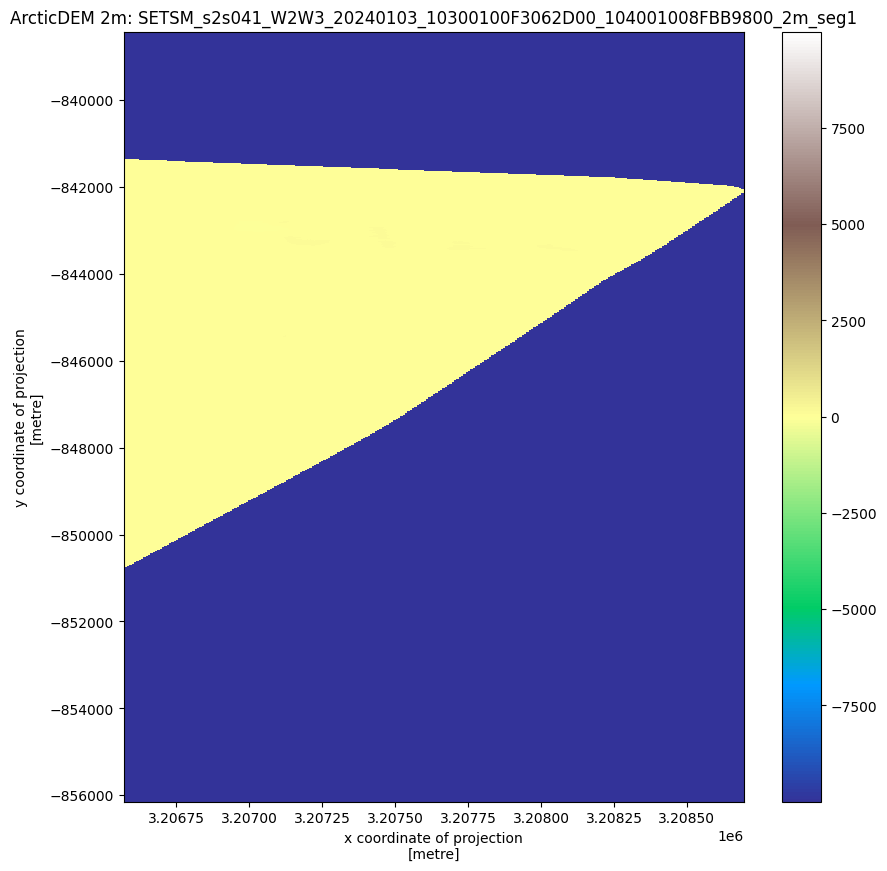

In [11]:
# ==============================================================================
# ARCTIC-DEM 2M DOWNLOADER (VIA PGC OFFICIAL API)
# Источник: https://github.com/awslabs/open-data-registry/blob/main/datasets/pgc-arcticdem.yaml
# ==============================================================================
!pip install -q pystac-client rioxarray geopandas rasterio

import os
import pystac_client
import rioxarray
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt

# 1. НАСТРОЙКИ
# Санкт-Петербург (примерный BBox центра)
# ВАЖНО: СПб находится на границе 60-й широты. ArcticDEM формально от 60°N, 
# но PGC API часто отдает данные и чуть южнее.
BBOX = [30.15, 59.85, 30.55, 60.05] 

OUTPUT_DIR = "spb_2m_strips"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. ПОДКЛЮЧЕНИЕ К ОФИЦИАЛЬНОМУ PGC API (НЕ MICROSOFT)
print("📡 Подключение к PGC STAC API...")
# Ссылка взята из документации, на которую указывает изученный YAML
PGC_STAC_URL = "https://stac.pgc.umn.edu/api/v1" 

client = pystac_client.Client.open(PGC_STAC_URL)

# 3. ПОИСК 2-МЕТРОВЫХ СТРИПОВ
print("🔍 Поиск снимков 2м разрешения...")
search = client.search(
    collections=["arcticdem-strips-s2s041-2m"], # Коллекция 2м стрипов (версия 4.1)
    bbox=BBOX,
    max_items=10
)

items = list(search.items())
print(f"✅ Найдено снимков: {len(items)}")

if not items:
    print("⚠️ Снимки не найдены. Возможные причины:")
    print("1. СПб находится южнее границы покрытия ArcticDEM (60°N).")
    print("2. Попробуйте расширить BBOX на север.")
else:
    # 4. ЗАГРУЗКА
    # Берем первый снимок (обычно самый свежий или лучший по покрытию)
    item = items[0]
    print(f"\n📥 Загрузка лучшего снимка: {item.id}")
    print(f"📅 Дата съемки: {item.datetime}")
    
    # Получаем ссылку на S3 (файл в бакете pgc-opendata-dems)
    # PGC API отдает ссылки http, которые редиректят на S3
    href = item.assets["dem"].href 
    
    try:
        # Открываем через rioxarray
        # PGC хранит данные как COG (Cloud Optimized GeoTIFF), поэтому качать весь файл не обязательно
        da = rioxarray.open_rasterio(href)
        
        # Обрезаем по нашему BBOX (чтобы не качать лишние гигабайты)
        # Сначала перепроецируем BBOX в проекцию снимка (обычно EPSG:3413)
        da_clipped = da.rio.clip_box(*BBOX, crs="EPSG:4326")
        
        # Сохраняем результат
        out_path = os.path.join(OUTPUT_DIR, "spb_arcticdem_2m_clipped.tif")
        da_clipped.rio.to_raster(out_path, compress='LZW')
        
        print(f"💾 Файл сохранен: {out_path}")
        
        # 5. БЫСТРЫЙ ПРОСМОТР
        plt.figure(figsize=(10, 10))
        da_clipped.plot(cmap='terrain', robust=True)
        plt.title(f"ArcticDEM 2m: {item.id}")
        plt.show()
        
    except Exception as e:
        print(f"❌ Ошибка загрузки: {e}")
        print("Попробуйте вручную скачать по ссылке:", href)

In [ ]:
# ======================================================================================
# FINAL ANALYSIS: LOCAL HIGH-RES DEM (2M)
# Обработка загруженного файла spb_arcticdem_2m_clipped.tif
# ======================================================================================

!pip install -q rioxarray geopandas osmnx folium rasterio mapclassify

import os
import numpy as np
import geopandas as gpd
import osmnx as ox
import rioxarray
from rasterio.features import shapes
from shapely.geometry import box
import folium
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# --------------------------------------------------------------------------------------
# 1. ЗАГРУЗКА ФАЙЛА
# --------------------------------------------------------------------------------------
FILENAME = "/kaggle/working/spb_2m_strips/spb_arcticdem_2m_clipped.tif"  # Имя вашего файла
FLOOD_LEVEL = 3.05 # Уровень катастрофического наводнения (м)
CRS_METRIC = "EPSG:32636" # Метрическая система для СПб (UTM 36N)

print(f"🚀 Загрузка файла: {FILENAME}...")

if not os.path.exists(FILENAME):
    print("❌ Файл не найден в текущей папке. Проверьте путь.")
else:
    # Открываем DEM
    dem = rioxarray.open_rasterio(FILENAME, masked=True)
    print(f"   Размер растра: {dem.shape}")
    print(f"   Исходная система координат: {dem.rio.crs}")

    # ----------------------------------------------------------------------------------
    # 2. ПОДГОТОВКА И КАЛИБРОВКА (CRITICAL STEP)
    # ----------------------------------------------------------------------------------
    print("🔄 Перепроецирование в метры (UTM 36N)...")
    dem = dem.rio.reproject(CRS_METRIC)
    
    # Авто-калибровка "нуля"
    # ArcticDEM - это DSM (поверхность). Вода там может быть не 0, а, например, -18м или +5м.
    # Мы найдем "воду" как самые низкие плоские участки и приравняем их к нулю.
    print("⚖️ Калибровка высот...")
    flat_vals = dem.values.flatten()
    valid_vals = flat_vals[~np.isnan(flat_vals)]
    valid_vals = valid_vals[valid_vals > -100] # убираем артефакты
    
    if len(valid_vals) > 0:
        # Берем 5-й перцентиль как уровень воды
        water_base = np.percentile(valid_vals, 5)
        print(f"   🔍 Базовый уровень воды в файле: {water_base:.2f} м")
        
        if abs(water_base) > 0.5:
            dem = dem - water_base
            print(f"   ✅ Рельеф сдвинут на {-water_base:.2f} м (калибровка).")
    
    # ----------------------------------------------------------------------------------
    # 3. МОДЕЛИРОВАНИЕ ЗАТОПЛЕНИЯ
    # ----------------------------------------------------------------------------------
    print(f"🌊 Расчет зоны затопления (уровень {FLOOD_LEVEL} м)...")
    
    flood_mask = dem <= FLOOD_LEVEL
    flood_mask = flood_mask.astype('uint8')
    
    # Векторизация (Raster -> Polygon)
    # Берем первый канал
    mask_arr = flood_mask.values[0] if len(flood_mask.shape) == 3 else flood_mask.values
    
    results = (
        {'properties': {'val': v}, 'geometry': s}
        for i, (s, v) in enumerate(shapes(mask_arr, mask=mask_arr==1, transform=dem.rio.transform()))
    )
    geoms = list(results)
    
    if not geoms:
        print("🎉 Затопления не обнаружено (весь рельеф выше уровня воды).")
    else:
        flood_poly = gpd.GeoDataFrame.from_features(geoms, crs=CRS_METRIC)
        flood_poly = flood_poly.dissolve() # Объединяем в один полигон
        
        print(f"   Площадь затопления: {flood_poly.area.sum() / 10000:.2f} га")

        # ------------------------------------------------------------------------------
        # 4. АНАЛИЗ ИНФРАСТРУКТУРЫ (OSM)
        # ------------------------------------------------------------------------------
        print("🏗️ Загрузка данных OSM для этой области...")
        
        # Получаем границы растра в Lat/Lon для запроса к OSM
        xmin, ymin, xmax, ymax = dem.rio.bounds()
        bbox_poly = gpd.GeoDataFrame({'geometry': [box(xmin, ymin, xmax, ymax)]}, crs=CRS_METRIC).to_crs("EPSG:4326")
        b_minx, b_miny, b_maxx, b_maxy = bbox_poly.total_bounds
        
        try:
            # Качаем землепользование
            landuse = ox.features_from_bbox(bbox=[b_miny, b_maxy, b_minx, b_maxx], tags={'landuse': True})
            
            if not landuse.empty:
                landuse = landuse.to_crs(CRS_METRIC)
                landuse = landuse[landuse.geometry.type.isin(['Polygon', 'MultiPolygon'])]
                
                # Пересечение (Overlay)
                print("💥 Расчет пострадавших объектов...")
                impact = gpd.overlay(landuse, flood_poly, how='intersection')
                impact['flooded_ha'] = impact.geometry.area / 10000
                
                # ОТЧЕТ
                print("\n📊 === ИТОГОВЫЙ ОТЧЕТ ПО УЩЕРБУ ===")
                stats = impact.groupby('landuse')['flooded_ha'].sum().sort_values(ascending=False)
                print(stats.head(10))
                
                # ----------------------------------------------------------------------
                # 5. ВИЗУАЛИЗАЦИЯ
                # ----------------------------------------------------------------------
                print("\n🗺️ Генерация карты...")
                
                # Центр карты
                cy, cx = (b_miny + b_maxy)/2, (b_minx + b_maxx)/2
                m = folium.Map(location=[cy, cx], zoom_start=14, tiles='CartoDB positron')
                
                # Слой воды
                # Упрощаем геометрию, так как 2м детализация очень тяжелая для браузера
                simple_flood = flood_poly.to_crs("EPSG:4326")
                simple_flood.geometry = simple_flood.geometry.simplify(5) 
                
                folium.GeoJson(
                    simple_flood,
                    name='Зона затопления',
                    style_function=lambda x: {'fillColor': '#00BFFF', 'color': 'none', 'fillOpacity': 0.6}
                ).add_to(m)
                
                # Слой объектов
                simple_impact = impact.to_crs("EPSG:4326")
                simple_impact.geometry = simple_impact.geometry.simplify(5)
                
                folium.GeoJson(
                    simple_impact,
                    name='Пострадавшие объекты',
                    style_function=lambda x: {'fillColor': '#FF4500', 'color': 'black', 'weight': 0.5, 'fillOpacity': 0.5},
                    tooltip=folium.GeoJsonTooltip(fields=['landuse', 'flooded_ha'], aliases=['Тип', 'Затоплено (га)'], localize=True)
                ).add_to(m)
                
                folium.LayerControl().add_to(m)
                m.save("result_map.html")
                print("✅ Карта сохранена: result_map.html")
                display(m) # Отображение в ноутбуке
                
            else:
                print("⚠️ В этой области OSM не нашел данных о землепользовании.")
                
        except Exception as e:
            print(f"Ошибка при работе с OSM: {e}")

🚀 Загрузка файла: /kaggle/working/spb_2m_strips/spb_arcticdem_2m_clipped.tif...
   Размер растра: (1, 8862, 1062)
   Исходная система координат: EPSG:3413
🔄 Перепроецирование в метры (UTM 36N)...
⚖️ Калибровка высот...
   🔍 Базовый уровень воды в файле: 20.36 м
   ✅ Рельеф сдвинут на -20.36 м (калибровка).
🌊 Расчет зоны затопления (уровень 3.05 м)...
   Площадь затопления: 243.87 га
🏗️ Загрузка данных OSM для этой области...
